# Grid and geolect-to-cell mappings

Every municipality with speakers (a geolect) is spread over the LV95 grid (`maloney.geo`) in one of
three modes (Ahmadi & Sennrich 2026); its cell weights sum to 1 in centroid and uniform mode:

- **centroid**: all weight in the cell of the municipality centroid
- **uniform**: spread evenly over the area of the municipality and its neighbours *in the same
  canton* (`NEIGHBOUR_DISTANCE`: 0 = municipalities sharing a border)
- **gaussian**: a kernel of `SIGMA` metres around the centroid

The first figure shows this for single municipalities, the second the sum over all of them.

In [13]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from maloney.data.stt4sg import read_geo_table, read_split
from maloney.geo import MODES, CellMapping, Geolects, Grid, Municipalities

DATA_DIR = Path("../data/stt4sg-350_v2-1")
GEO_DIR = Path("../data/geo")
SPLIT_DIR = DATA_DIR / "splits" / "smoke"  # or None for the official split
CELL_SIZE = 5_000         # metres
SIGMA = 10_000             # metres
NEIGHBOUR_DISTANCE = 2_000     # metres

meta = read_split(DATA_DIR, "train", split_dir=SPLIT_DIR).join(read_geo_table(DATA_DIR / "zip_municipality.csv"),
                                                               on="zipcode", how="inner")
geolects = Geolects.from_meta(meta)
grid = Grid.from_file(GEO_DIR / "cantons.geojson", CELL_SIZE)
munis = Municipalities(GEO_DIR / "municipalities.geojson")
mappings = {mode: CellMapping(mode, sigma=SIGMA, neighbour_distance=NEIGHBOUR_DISTANCE, municipalities=munis)
            for mode in MODES}
weights = {mode: mapping.weights(grid, geolects) for mode, mapping in mappings.items()}

cells = gpd.GeoDataFrame(geometry=grid.boxes, crs=2056)
cantons = gpd.GeoSeries(list(grid.regions.values()), crs=2056)
muni_shapes = gpd.GeoDataFrame({"bfs_nr": munis.bfs_nr}, geometry=munis.geometry, crs=2056)
print(grid, f"| {len(geolects)} municipalities, {geolects.n_clips.sum()} clips")

Grid(1842 active cells of 5 km, 70x45 from LV95 (2485000, 1075000)) | 40 municipalities, 15246 clips


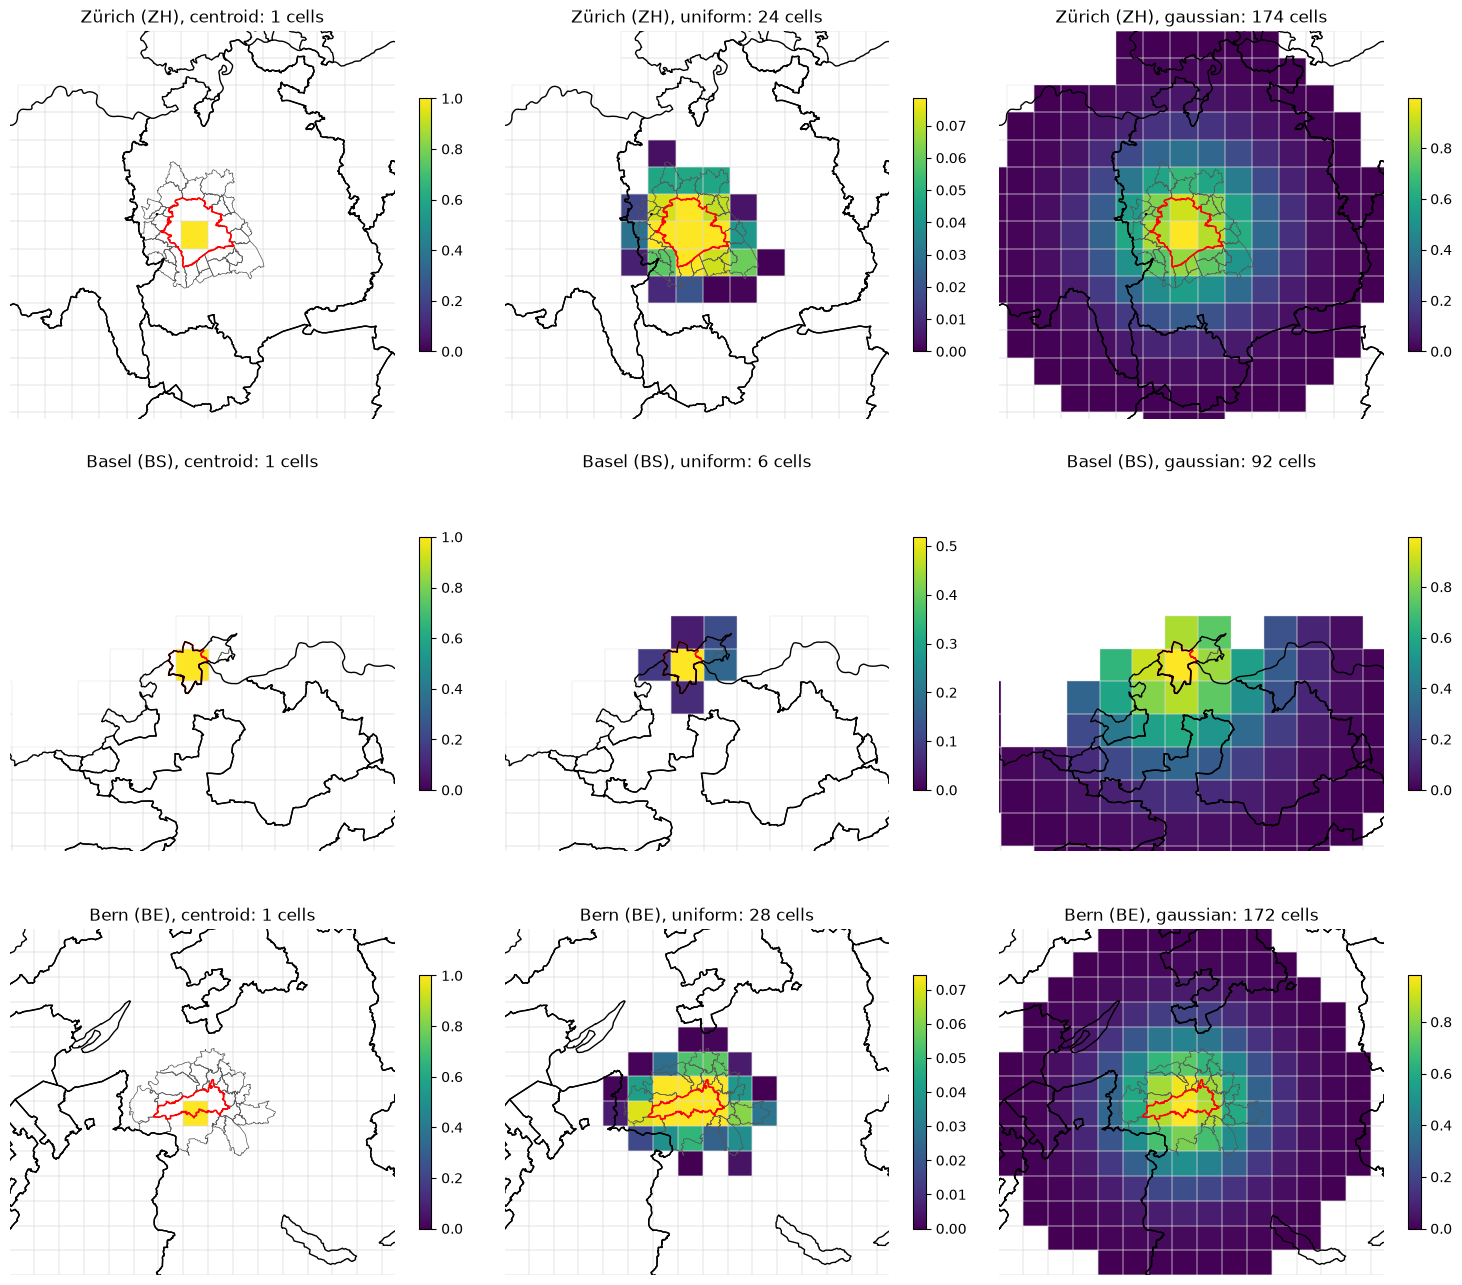

In [14]:
# One municipality per row: its region (red outline: itself, grey: its same-canton neighbours) and its cell weights.
EXAMPLES = [261, 2701, 351]  # Zürich, Basel, Bern; any BFS numbers, also without speakers
example = Geolects(np.array(EXAMPLES), np.array([munis.geometry[munis.index[b]].centroid.coords[0] for b in EXAMPLES]),
                   munis.canton[[munis.index[b] for b in EXAMPLES]], np.array(["-"] * len(EXAMPLES)), np.ones(len(EXAMPLES)))
example_weights = {mode: mapping.weights(grid, example) for mode, mapping in mappings.items()}

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(15, 4.5 * len(EXAMPLES)))
for row, bfs_nr in enumerate(EXAMPLES):
    region = muni_shapes.iloc[munis.neighbourhood(bfs_nr, NEIGHBOUR_DISTANCE)]
    xmin, ymin, xmax, ymax = region.total_bounds
    pad = max(xmax - xmin, ymax - ymin, 3 * SIGMA) * 0.8
    for ax, mode in zip(axes[row], MODES):
        w = example_weights[mode][row]
        cells.assign(w=w)[w > 0].plot(ax=ax, column="w", cmap="viridis", vmin=0, legend=True, legend_kwds={"shrink": 0.6})
        cells.boundary.plot(ax=ax, color="#dddddd", linewidth=0.3)
        region.boundary.plot(ax=ax, color="#555555", linewidth=0.5)
        muni_shapes[muni_shapes.bfs_nr == bfs_nr].boundary.plot(ax=ax, color="red", linewidth=1.2)
        cantons.boundary.plot(ax=ax, color="black", linewidth=1)
        ax.set_xlim(xmin - pad, xmax + pad)
        ax.set_ylim(ymin - pad, ymax + pad)
        ax.set_title(f"{munis.name[munis.index[bfs_nr]]} ({munis.canton[munis.index[bfs_nr]]}), {mode}: "
                     f"{(w > 0).sum()} cells")
        ax.set_axis_off()
plt.tight_layout()
plt.show()

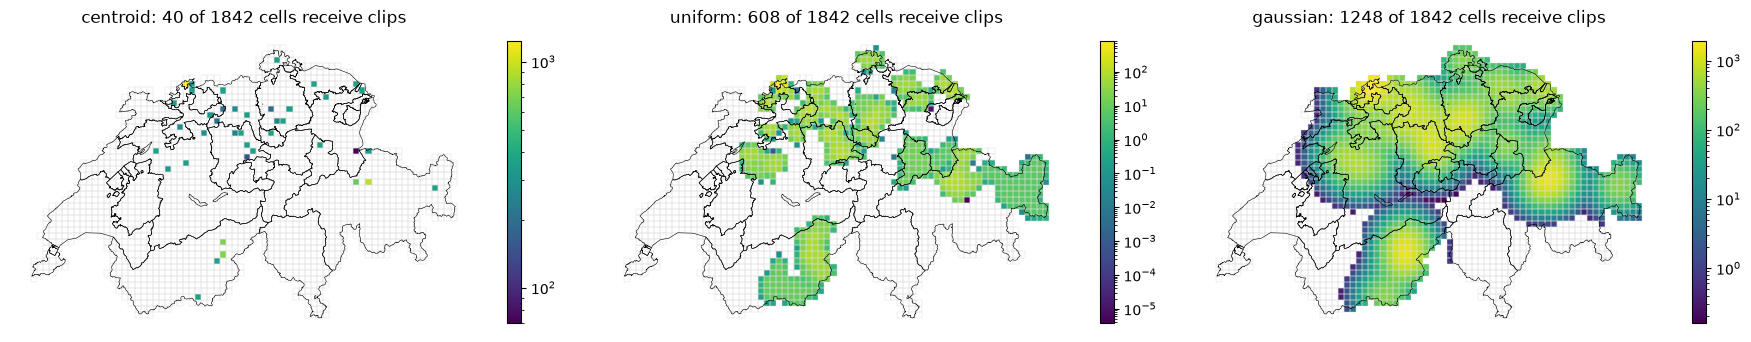

In [15]:
# All municipalities with speakers: clips per cell, sum over municipalities of clips x weight (log colour scale).
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, mode in zip(axes, MODES):
    mass = geolects.n_clips @ weights[mode]
    cells.boundary.plot(ax=ax, color="#dddddd", linewidth=0.3)
    cells.assign(mass=mass)[mass > 0].plot(ax=ax, column="mass", cmap="viridis", legend=True,
                                           norm=plt.matplotlib.colors.LogNorm(), legend_kwds={"shrink": 0.6})
    cantons.boundary.plot(ax=ax, color="black", linewidth=0.4)
    ax.set_title(f"{mode}: {(mass > 0).sum()} of {len(grid)} cells receive clips")
    ax.set_axis_off()
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()